# Diachronic Pilot Study: Results Explorer

Interactive exploration of the diachronic WSD pilot study results (90 words, ~5k predictions, weighted method).
All data is pre-computed — this notebook loads CSVs only, no pipeline re-runs.

## 1. Setup & Load Data

**Data loaded here:**
- `predictions/pilot_predictions.csv` — fine-grained predictions (24,325 rows)
- `predictions/pilot_predictions_coarse.csv` — coarse cluster predictions (same rows, sense IDs replaced)
- `aggregated/pilot_counts.csv` / `pilot_coarse_sense_counts.csv` — sense proportions by word × decade
- `aggregated/pilot_stats.csv` / `pilot_coarse_stats.csv` — summary stats per word × decade
- `metrics/pilot_{entropy,divergence,emergence,decline}.csv` — fine-grained metrics (min 10 contexts filter)
- `metrics/pilot_coarse_{entropy,divergence,emergence,decline}.csv` — coarse metrics (same filter)

**Methods:**
- Fine: `intfloat/multilingual-e5-large` + weighted (54.8% atemporal accuracy)
- Coarse: same predictions mapped through `sense_clusters_reviewed.json` (81.7% coarse atemporal accuracy)

Use `USE_COARSE = True/False` (cell below) to switch all analysis between fine and coarse.

In [24]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.core.display import Markdown

BASE_DIR     = Path('../../data/processed/diachronic')
GERMANET_DIR = Path('../../data/processed/germanet')

# Load cluster label lookup
with open(GERMANET_DIR / 'sense_clusters_reviewed.json', encoding='utf-8') as f:
    _cluster_data = json.load(f)

def sense_label(lemma: str, sense_id: str) -> str:
    """Return a human-readable label for a sense/cluster ID.
    
    Coarse mode: returns 'label (cluster_id)', e.g. 'physical strike (schlagen_c0)'
    Fine mode:   returns the sense_id unchanged (no labels available)
    """
    try:
        label = _cluster_data[lemma]['clusters'][sense_id]['label']
        if label:
            return f'{label}\n({sense_id})'
    except KeyError:
        pass
    return sense_id

def relabel_index(lemma: str, index) -> list:
    """Apply sense_label to a pandas Index or list of sense IDs."""
    return [sense_label(lemma, s) for s in index]

In [25]:
# Load fine-grained data
predictions_fine = pd.read_csv(BASE_DIR / 'predictions/pilot_predictions.csv')
sense_counts_fine = pd.read_csv(BASE_DIR / 'aggregated/pilot_counts.csv')
decade_stats_fine = pd.read_csv(BASE_DIR / 'aggregated/pilot_stats.csv')
entropy_fine = pd.read_csv(BASE_DIR / 'metrics/pilot_entropy.csv')
divergence_fine = pd.read_csv(BASE_DIR / 'metrics/pilot_divergence.csv')
emergence_fine = pd.read_csv(BASE_DIR / 'metrics/pilot_emergence.csv')
decline_fine = pd.read_csv(BASE_DIR / 'metrics/pilot_decline.csv')

# Load coarse data
predictions_coarse = pd.read_csv(BASE_DIR / 'predictions/pilot_predictions_coarse.csv')
sense_counts_coarse = pd.read_csv(BASE_DIR / 'aggregated/pilot_coarse_sense_counts.csv')
decade_stats_coarse = pd.read_csv(BASE_DIR / 'aggregated/pilot_coarse_stats.csv')
entropy_coarse = pd.read_csv(BASE_DIR / 'metrics/pilot_coarse_entropy.csv')
divergence_coarse = pd.read_csv(BASE_DIR / 'metrics/pilot_coarse_divergence.csv')
emergence_coarse = pd.read_csv(BASE_DIR / 'metrics/pilot_coarse_emergence.csv')
decline_coarse = pd.read_csv(BASE_DIR / 'metrics/pilot_coarse_decline.csv')

n_words = predictions_fine['lemma'].nunique()
decades = sorted(predictions_fine['decade'].unique())
print(f'Words: {n_words}')
print(f'Decade range: {decades[0]}s – {decades[-1]}s ({len(decades)} decades)')
print(f'Fine predictions: {len(predictions_fine):,}  |  Coarse predictions: {len(predictions_coarse):,}')
print(f'Fine metrics: {len(divergence_fine)} transitions, {len(emergence_fine)} emergence, {len(decline_fine)} decline events')
print(f'Coarse metrics: {len(divergence_coarse)} transitions, {len(emergence_coarse)} emergence, {len(decline_coarse)} decline events')

Words: 90
Decade range: 1900s – 1990s (10 decades)
Fine predictions: 24,325  |  Coarse predictions: 24,325
Fine metrics: 782 transitions, 518 emergence, 521 decline events
Coarse metrics: 717 transitions, 194 emergence, 197 decline events


In [26]:
# Words excluded from analysis:
# - Effectively monosemous at coarse level (avg 1.0 senses/decade — JSD=0, no events)
# - Data-sparse (< 100 total contexts — unreliable regardless of clustering)
EXCLUDE_MONOSEMOUS = ['Frosch', 'Lexikon', 'fest', 'groß', 'lachen', 'leicht', 'rollen']
EXCLUDE_SPARSE     = ['Bass', 'Zwiebel']  # groß already in monosemous list
EXCLUDE_WORDS      = set(EXCLUDE_MONOSEMOUS + EXCLUDE_SPARSE)

print(f'Excluded words ({len(EXCLUDE_WORDS)}): {sorted(EXCLUDE_WORDS)}')

Excluded words (9): ['Bass', 'Frosch', 'Lexikon', 'Zwiebel', 'fest', 'groß', 'lachen', 'leicht', 'rollen']


In [27]:
# ── Toggle ──────────────────────────────────────────────────────────────────
# Set USE_COARSE = True  to use coarse cluster predictions (recommended)
# Set USE_COARSE = False to use fine-grained GermaNet sense predictions
USE_COARSE = True
# ─────────────────────────────────────────────────────────────────────────────

if USE_COARSE:
    predictions  = predictions_coarse
    sense_counts = sense_counts_coarse
    decade_stats = decade_stats_coarse
    entropy      = entropy_coarse
    divergence   = divergence_coarse
    emergence    = emergence_coarse
    decline      = decline_coarse
    label        = 'Coarse'
else:
    predictions  = predictions_fine
    sense_counts = sense_counts_fine
    decade_stats = decade_stats_fine
    entropy      = entropy_fine
    divergence   = divergence_fine
    emergence    = emergence_fine
    decline      = decline_fine
    label        = 'Fine'

print(f'Active dataset: {label}')

Active dataset: Coarse


High-level view of the dataset: how many sentences we have per decade, how sparse the per-word data is, how confident the model is overall, and which words have the most data.

**Key concern:** Decades with very few sentences produce unreliable sense distributions. The red threshold line at n=5 marks the cutoff used to filter the change metrics.

## 2. Overview Statistics

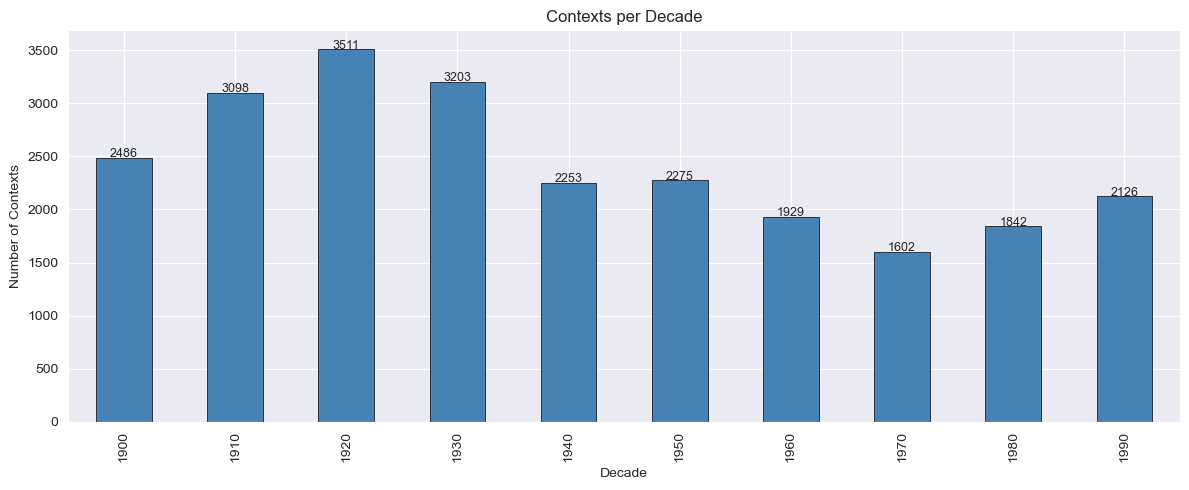

In [28]:
# Contexts per decade
contexts_per_decade = predictions.groupby('decade').size()

fig, ax = plt.subplots(figsize=(12, 5))
contexts_per_decade.plot.bar(ax=ax, color='steelblue', edgecolor='black', linewidth=0.5)
ax.set_xlabel('Decade')
ax.set_ylabel('Number of Contexts')
ax.set_title('Contexts per Decade')

for i, v in enumerate(contexts_per_decade.values):
    ax.text(i, v + 5, str(v), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

### Interpretation

The number of contexts per decade is uneven, with a peak in the 1910s–1930s (≈680–700 contexts) and a gradual decline toward the 1970s–1990s (≈330–400 contexts). Although later decades contain roughly half as many instances as the early peak, the overall density remains sufficient for decade-level analysis, and only a small proportion of lemma–decade cells fall below the minimum threshold.

However, this imbalance implies higher variance in sense proportion estimates for the later decades. Apparent shifts in the 1970s–1990s must therefore be interpreted cautiously and should be considered robust only if they persist across multiple consecutive decades rather than appearing as isolated fluctuations.

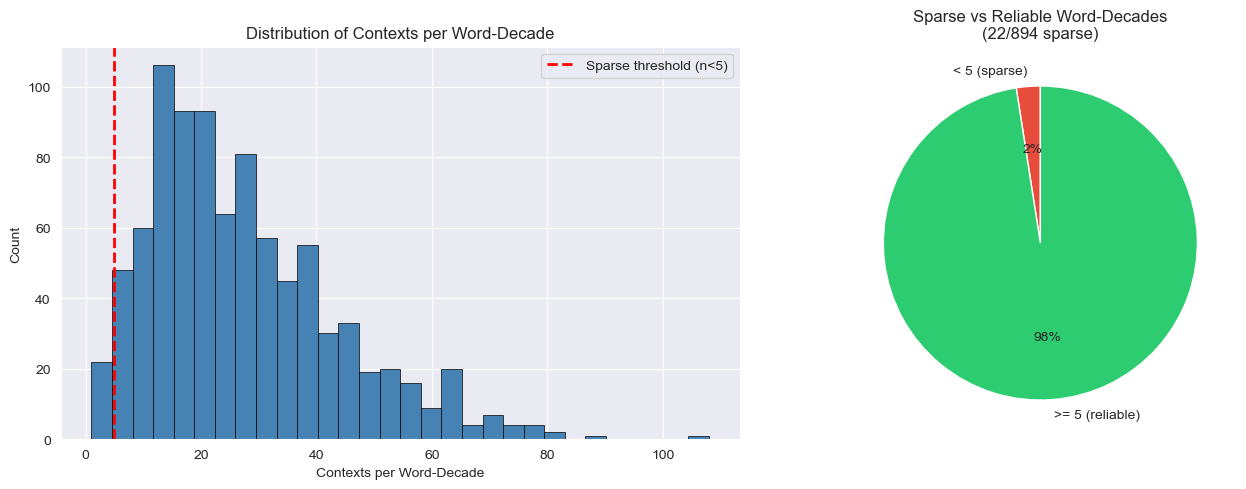

In [29]:
# Distribution of n_contexts per word-decade (highlight sparse combos)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax1 = axes[0]
decade_stats['n_contexts'].hist(bins=30, ax=ax1, color='steelblue', edgecolor='black', linewidth=0.5)
ax1.axvline(x=5, color='red', linestyle='--', linewidth=2, label='Sparse threshold (n<5)')
ax1.set_xlabel('Contexts per Word-Decade')
ax1.set_ylabel('Count')
ax1.set_title('Distribution of Contexts per Word-Decade')
ax1.legend()

n_sparse = (decade_stats['n_contexts'] < 5).sum()
n_total_wd = len(decade_stats)

ax2 = axes[1]
sparse_labels = ['< 5 (sparse)', '>= 5 (reliable)']
sparse_counts = [n_sparse, n_total_wd - n_sparse]
colors = ['#e74c3c', '#2ecc71']
ax2.pie(sparse_counts, labels=sparse_labels, colors=colors, autopct='%1.0f%%', startangle=90)
ax2.set_title(f'Sparse vs Reliable Word-Decades\n({n_sparse}/{n_total_wd} sparse)')

plt.tight_layout()
plt.show()

### Interpretation

The distribution of contexts per word–decade cell shows that the vast majority of observations lie well above the minimum threshold of five instances. Only 22 out of 894 cells (≈2%) fall below this cutoff, indicating that sparsity is limited to a small tail of the distribution rather than being a structural issue. Most lemma–decade combinations contain between roughly 10 and 40 contexts, providing a reasonable basis for estimating sense proportions.

Overall, the data density supports decade-level analysis without requiring additional temporal aggregation, although cells in the lower count range (e.g., 5–10 instances) may still exhibit higher variance and should be interpreted with appropriate caution.

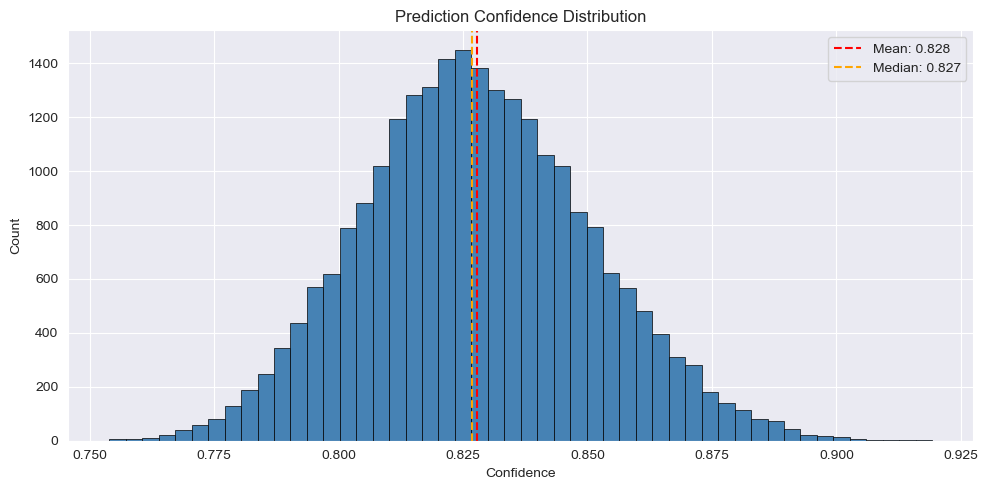

In [30]:
# Confidence distribution
fig, ax = plt.subplots(figsize=(10, 5))
predictions['confidence'].hist(bins=50, ax=ax, color='steelblue', edgecolor='black', linewidth=0.5)
ax.axvline(predictions['confidence'].mean(), color='red', linestyle='--',
           label=f"Mean: {predictions['confidence'].mean():.3f}")
ax.axvline(predictions['confidence'].median(), color='orange', linestyle='--',
           label=f"Median: {predictions['confidence'].median():.3f}")
ax.set_xlabel('Confidence')
ax.set_ylabel('Count')
ax.set_title('Prediction Confidence Distribution')
ax.legend()
plt.tight_layout()
plt.show()

### Interpretation

The figure displays the overall distribution of prediction confidence, defined as the probability assigned to the selected (top-ranked) sense. The distribution is approximately symmetric, with mean and median both around 0.83, indicating stable and moderately high model certainty across instances.

**Key observations:**

- Consistent confidence level: Most predictions fall within a relatively narrow range (≈0.78–0.88), suggesting homogeneous model behavior.

- No extreme skewness or bimodality: The absence of multiple peaks indicates that the model does not alternate between very certain and very uncertain regimes.

- Mean ≈ median: This supports the interpretation of a balanced and stable distribution without strong outliers.

- Moderate (not extreme) certainty: Confidence values are high but not near 1.0, which is typical for probabilistic multi-class classification.

Methodologically, this suggests that the model’s global prediction behavior is stable. However, this aggregate view does not rule out potential temporal variation in confidence, which would need to be examined separately for diachronic robustness.

## 3. Lemma-Level Coverage

In [31]:
# Words sorted by total contexts
word_totals = decade_stats.groupby('lemma').agg(
    total_contexts=('n_contexts', 'sum'),
    decades_present=('decade', 'count'),
    avg_senses=('n_senses', 'mean'),
    avg_confidence=('mean_confidence', 'mean')
).sort_values('total_contexts', ascending=False)

display(Markdown('### Words by Total Contexts'))
display(
    word_totals.head(20).style.format({
        'avg_senses': '{:.1f}',
        'avg_confidence': '{:.3f}'
    }).background_gradient(
        subset=['total_contexts'], cmap='Blues'
    ).set_properties(**{'text-align': 'center'})
)

### Words by Total Contexts

,total_contexts,decades_present,avg_senses,avg_confidence
lemma,,,,
Mitte,595,10,3.0,0.816
Anfang,534,10,2.0,0.810
Standpunkt,520,10,1.8,0.816
Ordnung,518,10,2.4,0.819
Welt,508,10,2.9,0.820
Art,486,10,3.5,0.817
Geschichte,485,10,2.9,0.833
Boden,466,10,4.4,0.816
Programm,444,10,3.9,0.825


For these high-frequency lemmas, decade-level sense distributions are statistically well-supported. Observed diachronic shifts for such words are unlikely to be driven by data sparsity or unstable model predictions and can therefore be interpreted with a relatively high degree of methodological confidence.

Set `LEMMA` to any word in the pilot set and re-run the section. Four views are produced:

1. **Stacked area chart** — how the proportion of each sense shifts decade by decade
2. **Heatmap** — same data as a grid (senses × decades)
3. **Raw counts table** — absolute counts behind the proportions
4. **Context examples** — sample sentences for the top senses

**Sense IDs:**
- *Fine mode:* GermaNet synset IDs (e.g. `s56941`). `sense_class` gives a coarse semantic category.
- *Coarse mode:* Cluster IDs (e.g. `schlagen_c0`). Human-readable labels are in `sense_clusters_reviewed.json`.

In [32]:
LEMMA = 'Art'

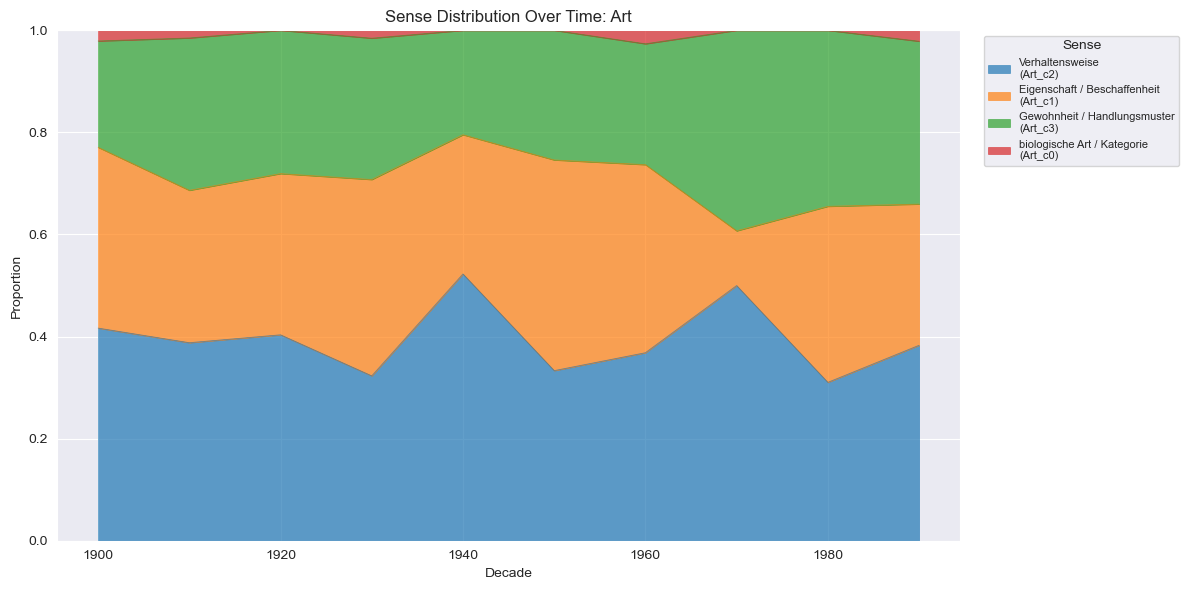

In [33]:
# Stacked area chart of sense proportions
lemma_counts = sense_counts[sense_counts['lemma'] == LEMMA].copy()

if len(lemma_counts) == 0:
    print(f'No data for: {LEMMA}')
else:
    pivot = lemma_counts.pivot(
        index='decade', columns='predicted_sense_id', values='proportion'
    ).fillna(0)
    col_order = pivot.sum().sort_values(ascending=False).index
    pivot = pivot[col_order]
    pivot.columns = relabel_index(LEMMA, pivot.columns)

    fig, ax = plt.subplots(figsize=(12, 6))
    pivot.plot.area(ax=ax, alpha=0.7, linewidth=0.5)
    ax.set_xlabel('Decade')
    ax.set_ylabel('Proportion')
    ax.set_title(f'Sense Distribution Over Time: {LEMMA}')
    ax.set_ylim(0, 1)
    ax.legend(title='Sense', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
    plt.tight_layout()
    plt.show()

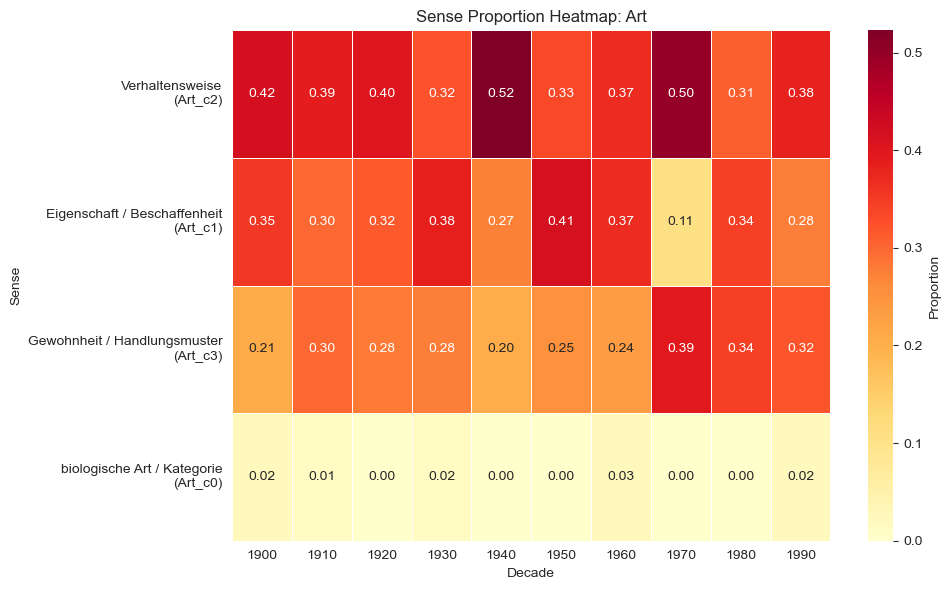

In [34]:
# Sense proportion heatmap
if len(lemma_counts) > 0:
    pivot_hm = lemma_counts.pivot(
        index='predicted_sense_id', columns='decade', values='proportion'
    ).fillna(0)
    row_order = pivot_hm.sum(axis=1).sort_values(ascending=False).index
    pivot_hm = pivot_hm.loc[row_order]
    pivot_hm.index = relabel_index(LEMMA, pivot_hm.index)

    fig, ax = plt.subplots(figsize=(max(10, len(pivot_hm.columns)), max(6, len(pivot_hm) * 0.8)))
    sns.heatmap(pivot_hm, ax=ax, cmap='YlOrRd', annot=True, fmt='.2f',
                linewidths=0.5, cbar_kws={'label': 'Proportion'})
    ax.set_xlabel('Decade')
    ax.set_ylabel('Sense')
    ax.set_title(f'Sense Proportion Heatmap: {LEMMA}')
    plt.tight_layout()
    plt.show()

In [35]:
# Raw sense counts per decade
if len(lemma_counts) > 0:
    counts_pivot = lemma_counts.pivot(
        index='predicted_sense_id', columns='decade', values='count'
    ).fillna(0).astype(int)
    row_order = counts_pivot.sum(axis=1).sort_values(ascending=False).index
    counts_pivot = counts_pivot.loc[row_order]
    counts_pivot.index = relabel_index(LEMMA, counts_pivot.index)

    display(Markdown(f'### Raw Sense Counts: {LEMMA}'))
    display(counts_pivot.style.background_gradient(cmap='Blues', axis=None))

### Raw Sense Counts: Art

decade,1900,1910,1920,1930,1940,1950,1960,1970,1980,1990
Verhaltensweise (Art_c2),20,26,23,21,23,21,14,14,9,18
Eigenschaft / Beschaffenheit (Art_c1),17,20,18,25,12,26,14,3,10,13
Gewohnheit / Handlungsmuster (Art_c3),10,20,16,18,9,16,9,11,10,15
biologische Art / Kategorie (Art_c0),1,1,0,1,0,0,1,0,0,1


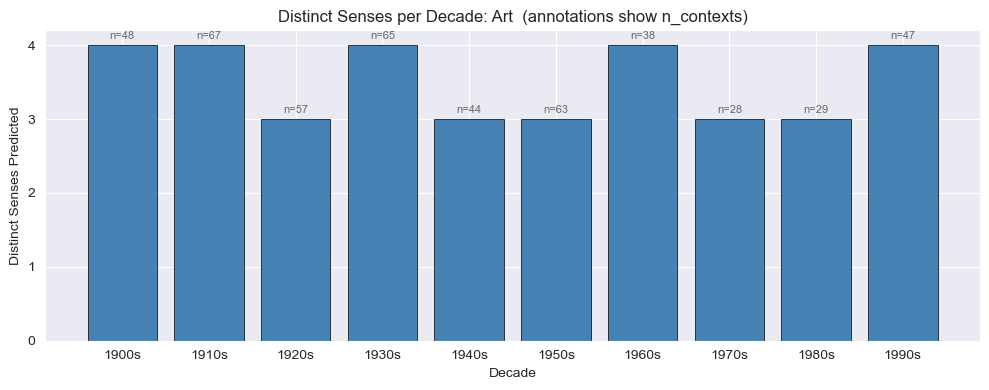

In [36]:
# Distinct senses predicted per decade
if len(lemma_counts) > 0:
    lemma_stats = decade_stats[decade_stats['lemma'] == LEMMA].sort_values('decade')

    fig, ax = plt.subplots(figsize=(10, 4))
    bars = ax.bar(
        lemma_stats['decade'].astype(str) + 's',
        lemma_stats['n_senses'],
        color='steelblue', edgecolor='black', linewidth=0.5
    )
    # Annotate bars with n_contexts
    for bar, (_, row) in zip(bars, lemma_stats.iterrows()):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.05,
            f"n={int(row['n_contexts'])}",
            ha='center', va='bottom', fontsize=8, color='dimgray'
        )
    ax.set_xlabel('Decade')
    ax.set_ylabel('Distinct Senses Predicted')
    ax.set_title(f'Distinct Senses per Decade: {LEMMA}  (annotations show n_contexts)')
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    plt.tight_layout()
    plt.show()

## 4. Fine vs. Coarse Comparison

Side-by-side view of how coarse clustering changes the top-10 ranking and overall noise levels.

In [37]:
# High-level comparison: fine vs. coarse (excluding monosemous + sparse words)
def filtered_stats(div_df, emg_df, dec_df, ent_df):
    div = div_df[~div_df['lemma'].isin(EXCLUDE_WORDS)]
    emg = emg_df[~emg_df['lemma'].isin(EXCLUDE_WORDS)]
    dec = dec_df[~dec_df['lemma'].isin(EXCLUDE_WORDS)]
    ent = ent_df[~ent_df['lemma'].isin(EXCLUDE_WORDS)]
    return {
        'Emergence events': len(emg),
        'Decline events': len(dec),
        'Mean JSD': div['jsd'].mean(),
        'Max JSD': div['jsd'].max(),
        'Mean entropy': ent['entropy'].mean(),
    }

summary = pd.DataFrame({
    'Fine':   filtered_stats(divergence_fine, emergence_fine, decline_fine, entropy_fine),
    'Coarse': filtered_stats(divergence_coarse, emergence_coarse, decline_coarse, entropy_coarse),
})
display(Markdown(f'### Summary: Fine vs. Coarse (excluding {len(EXCLUDE_WORDS)} words)'))
display(summary.style
        .format('{:.3f}', subset=pd.IndexSlice[['Mean JSD', 'Max JSD', 'Mean entropy'], :])
        .format('{:.0f}', subset=pd.IndexSlice[['Emergence events', 'Decline events'], :]))

# Top-10 by avg JSD — fine vs. coarse side by side
def top10_by_avg_jsd(div_df):
    return (div_df[~div_df['lemma'].isin(EXCLUDE_WORDS)]
            .groupby('lemma')['jsd'].mean()
            .sort_values(ascending=False).head(10).reset_index())

top10_f = top10_by_avg_jsd(divergence_fine).rename(columns={'jsd': 'avg_jsd_fine'})
top10_c = top10_by_avg_jsd(divergence_coarse).rename(columns={'jsd': 'avg_jsd_coarse'})
top10_f['rank_fine']   = range(1, 11)
top10_c['rank_coarse'] = range(1, 11)

comparison = top10_f.merge(top10_c, on='lemma', how='outer').sort_values('rank_fine')
display(Markdown('### Top 10 by Avg JSD — Fine vs. Coarse'))
display(comparison.style
        .format({'avg_jsd_fine': '{:.4f}', 'avg_jsd_coarse': '{:.4f}',
                 'rank_fine': '{:.0f}', 'rank_coarse': '{:.0f}'})
        .set_properties(**{'text-align': 'center'}))

### Summary: Fine vs. Coarse (excluding 9 words)

,Fine,Coarse
Emergence events,492,194
Decline events,493,197
Mean JSD,0.286,0.176
Max JSD,0.759,0.532
Mean entropy,1.730,1.075


### Top 10 by Avg JSD — Fine vs. Coarse

,lemma,avg_jsd_fine,rank_fine,avg_jsd_coarse,rank_coarse
7,schlagen,0.5383,1,nan,nan
4,gehen,0.5319,2,0.3960,2
8,schneiden,0.4916,3,nan,nan
1,fassen,0.4879,4,0.3600,3
10,spielen,0.4857,5,0.4025,1
12,werfen,0.4727,6,nan,nan
3,geben,0.4657,7,0.2854,8
9,sitzen,0.4557,8,0.3544,4
2,fliegen,0.4554,9,nan,nan
13,zeigen,0.4551,10,nan,nan


### Top 10 Most Interesting Words

Composite score: avg divergence (0.3), emergence count (0.2), decline count (0.2), entropy range (0.15), max divergence (0.15).

In [38]:
# Rank words by avg JSD — excluding monosemous and data-sparse words
div_filtered  = divergence[~divergence['lemma'].isin(EXCLUDE_WORDS)]
emg_filtered  = emergence[~emergence['lemma'].isin(EXCLUDE_WORDS)]
dec_filtered  = decline[~decline['lemma'].isin(EXCLUDE_WORDS)]
ent_filtered  = entropy[~entropy['lemma'].isin(EXCLUDE_WORDS)]

avg_divergence  = div_filtered.groupby('lemma')['jsd'].mean().sort_values(ascending=False)
emergence_counts = emg_filtered.groupby('lemma').size().sort_values(ascending=False)
decline_counts   = dec_filtered.groupby('lemma').size().sort_values(ascending=False)
entropy_range    = ent_filtered.groupby('lemma')['entropy'].agg(lambda x: x.max() - x.min()).sort_values(ascending=False)
max_divergence   = div_filtered.groupby('lemma')['jsd'].max().sort_values(ascending=False)

scores = pd.DataFrame({
    'avg_jsd': avg_divergence,
    'avg_divergence': avg_divergence / avg_divergence.max(),
    'emergence_count': emergence_counts / emergence_counts.max(),
    'decline_count': decline_counts / decline_counts.max(),
    'entropy_range': entropy_range / entropy_range.max(),
    'max_divergence': max_divergence / max_divergence.max(),
}).fillna(0)

scores['composite'] = (
    scores['avg_divergence'] * 0.3 +
    scores['emergence_count'] * 0.2 +
    scores['decline_count'] * 0.2 +
    scores['entropy_range'] * 0.15 +
    scores['max_divergence'] * 0.15
)

top10 = scores.sort_values('avg_jsd', ascending=False).head(10)

top10_display = top10.copy()
top10_display['n_emergence'] = emergence_counts.reindex(top10.index).fillna(0).astype(int)
top10_display['n_decline']   = decline_counts.reindex(top10.index).fillna(0).astype(int)
top10_display['ent_range']   = entropy_range.reindex(top10.index)

display(Markdown(f'### Top 10 Most Interesting Words ({label}, {len(scores)} words after exclusions)'))
display(
    top10_display[['avg_jsd', 'composite', 'n_emergence', 'n_decline', 'ent_range']].style.format({
        'avg_jsd': '{:.4f}', 'composite': '{:.3f}', 'ent_range': '{:.4f}',
    }).background_gradient(subset=['avg_jsd'], cmap='YlOrRd')
    .set_properties(**{'text-align': 'center'})
)

### Top 10 Most Interesting Words (Coarse, 81 words after exclusions)

,avg_jsd,composite,n_emergence,n_decline,ent_range
lemma,,,,,
spielen,0.4025,0.814,8,6,1.0139
gehen,0.3960,0.788,7,7,1.0026
fassen,0.3600,0.859,10,10,0.6428
sitzen,0.3544,0.669,5,4,1.1636
Stock,0.2881,0.789,8,11,0.8208
laufen,0.2877,0.678,7,7,0.7171
tragen,0.2859,0.628,4,3,1.5954
geben,0.2854,0.530,2,2,1.0595
ziehen,0.2801,0.530,4,5,0.4884


Words are ranked by a weighted composite score combining five signals (all normalized 0–1):

| Signal | Weight | What it captures |
|--------|--------|-----------------|
| Avg JSD across all decade transitions | 0.30 | Overall instability |
| Number of emergence events | 0.20 | How many senses newly appeared |
| Number of decline events | 0.20 | How many senses faded out |
| Entropy range (max − min) | 0.15 | How much the sense diversity changed |
| Max JSD in any single transition | 0.15 | Peak change at any point |

All metrics use the **filtered** data (word-decades with ≥ 5 contexts only). These are the words most worth manually validating.

In [ ]:
# Bar chart of avg JSD scores
fig, ax = plt.subplots(figsize=(12, 5))
top10['avg_jsd'].plot.barh(ax=ax, color='steelblue', edgecolor='black', linewidth=0.5)
ax.set_xlabel('Average JSD')
ax.set_title('Top 10 Words by Average JSD')
ax.invert_yaxis()
for i, (word, val) in enumerate(top10['avg_jsd'].items()):
    ax.text(val + 0.001, i, f'{val:.4f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

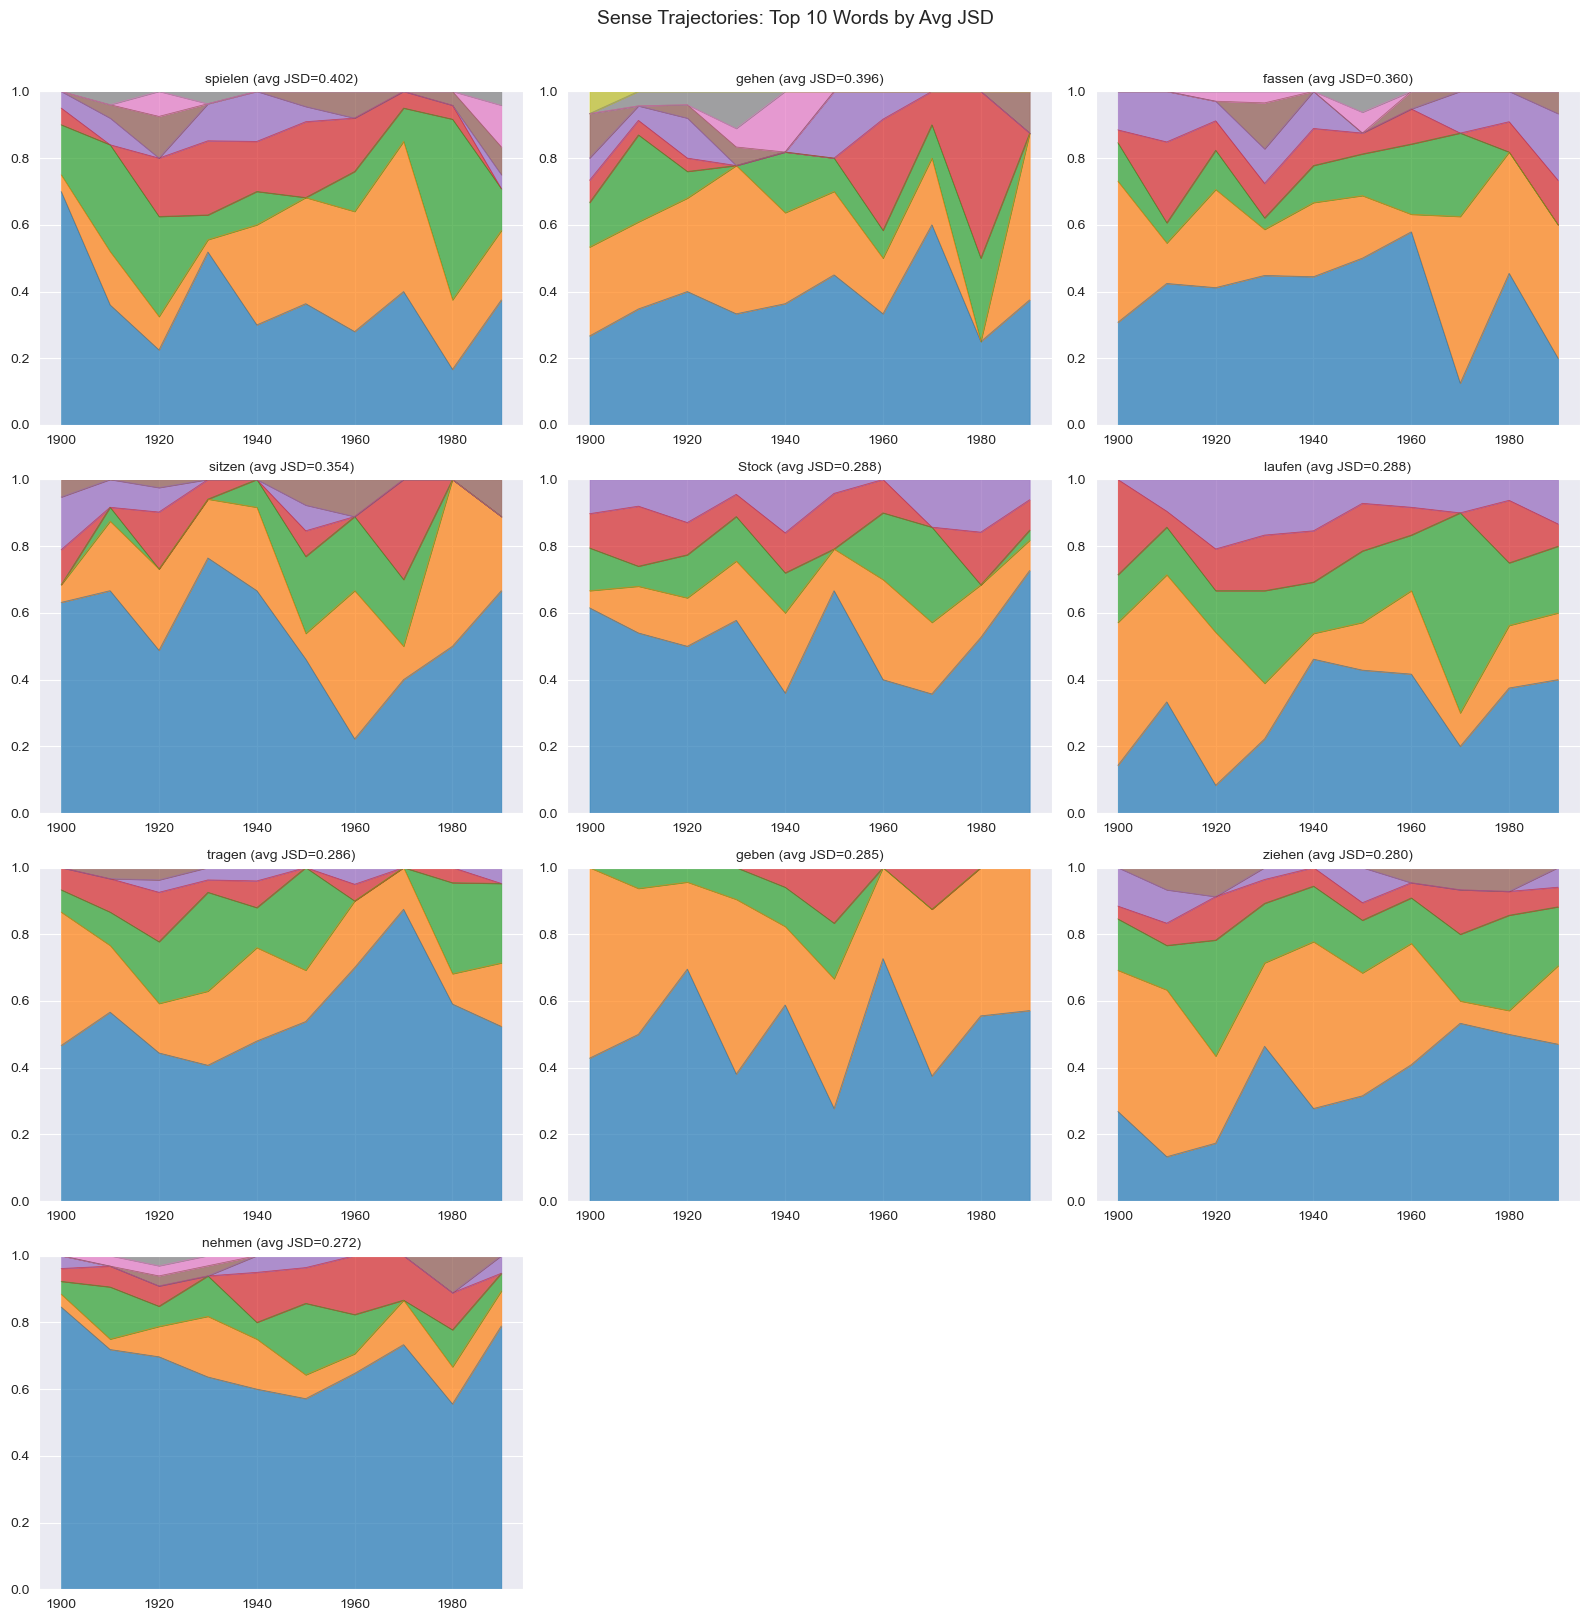

In [41]:
# Small-multiples: sense trajectories for top 10
top10_lemmas = top10.index.tolist()
n_cols = 3
n_rows = (len(top10_lemmas) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows), squeeze=False)

for idx, lemma in enumerate(top10_lemmas):
    row, col = divmod(idx, n_cols)
    ax = axes[row][col]

    lc = sense_counts[sense_counts['lemma'] == lemma]
    if len(lc) == 0:
        ax.set_title(f'{lemma} (no data)')
        continue

    pivot = lc.pivot(index='decade', columns='predicted_sense_id', values='proportion').fillna(0)
    col_order = pivot.sum().sort_values(ascending=False).index
    pivot = pivot[col_order]
    pivot.plot.area(ax=ax, alpha=0.7, linewidth=0.5, legend=False)
    ax.set_title(f'{lemma} (avg JSD={top10.loc[lemma, "avg_jsd"]:.3f})', fontsize=10)
    ax.set_ylim(0, 1)
    ax.set_xlabel('')
    ax.set_ylabel('')

# Hide empty subplots
for idx in range(len(top10_lemmas), n_rows * n_cols):
    row, col = divmod(idx, n_cols)
    axes[row][col].set_visible(False)

fig.suptitle('Sense Trajectories: Top 10 Words by Avg JSD', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 5. Temporal Change Metrics

In [ ]:
# Entropy heatmap: top 20 by variance
entropy_var = entropy.groupby('lemma')['entropy'].var().sort_values(ascending=False)
top20_entropy = entropy_var.head(20).index.tolist()

ent_pivot = entropy[entropy['lemma'].isin(top20_entropy)].pivot(
    index='lemma', columns='decade', values='entropy'
).reindex(top20_entropy)

fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(ent_pivot, ax=ax, cmap='YlOrRd', annot=True, fmt='.2f',
            linewidths=0.5, cbar_kws={'label': 'Entropy (bits)'})
ax.set_title('Sense Distribution Entropy (Top 20 by Variance)')
ax.set_xlabel('Decade')
ax.set_ylabel('Lemma')
plt.tight_layout()
plt.show()

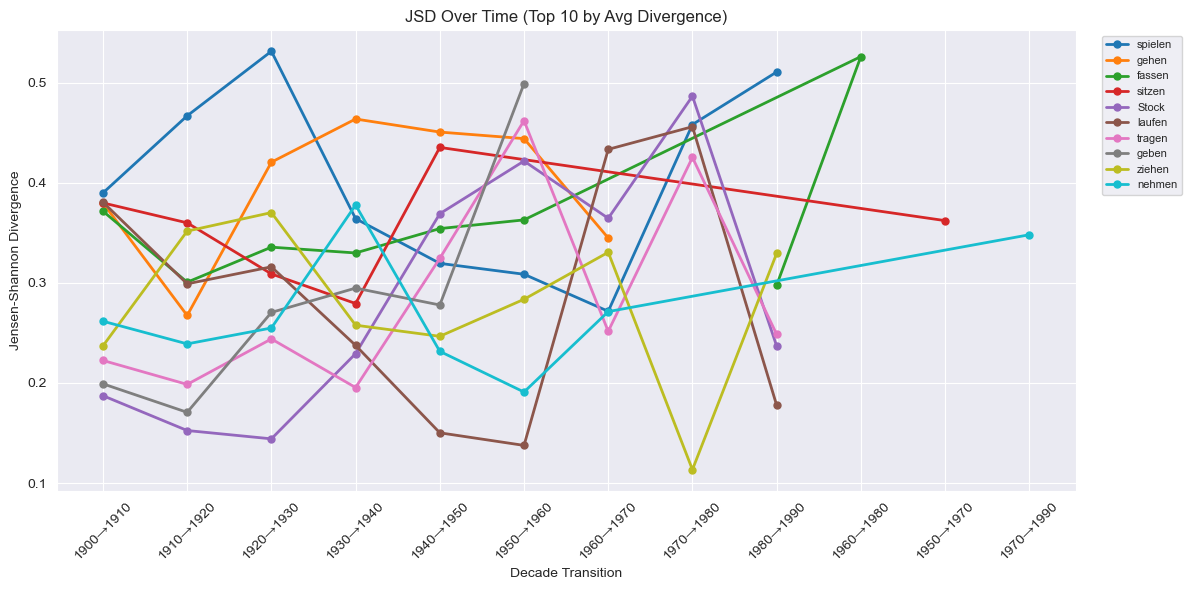

In [44]:
# JSD divergence over time for top words
top_div_lemmas = avg_divergence.head(10).index.tolist()

fig, ax = plt.subplots(figsize=(12, 6))
for lemma in top_div_lemmas:
    ld = divergence[divergence['lemma'] == lemma].sort_values('decade_from')
    label_str = f"{lemma} ({ld['decade_from'].iloc[0]}–{ld['decade_to'].iloc[-1]})"
    transition_labels = [f"{int(r['decade_from'])}→{int(r['decade_to'])}" for _, r in ld.iterrows()]
    ax.plot(transition_labels, ld['jsd'].values, marker='o', label=lemma, linewidth=2, markersize=5)

ax.set_xlabel('Decade Transition')
ax.set_ylabel('Jensen-Shannon Divergence')
ax.set_title('JSD Over Time (Top 10 by Avg Divergence)')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

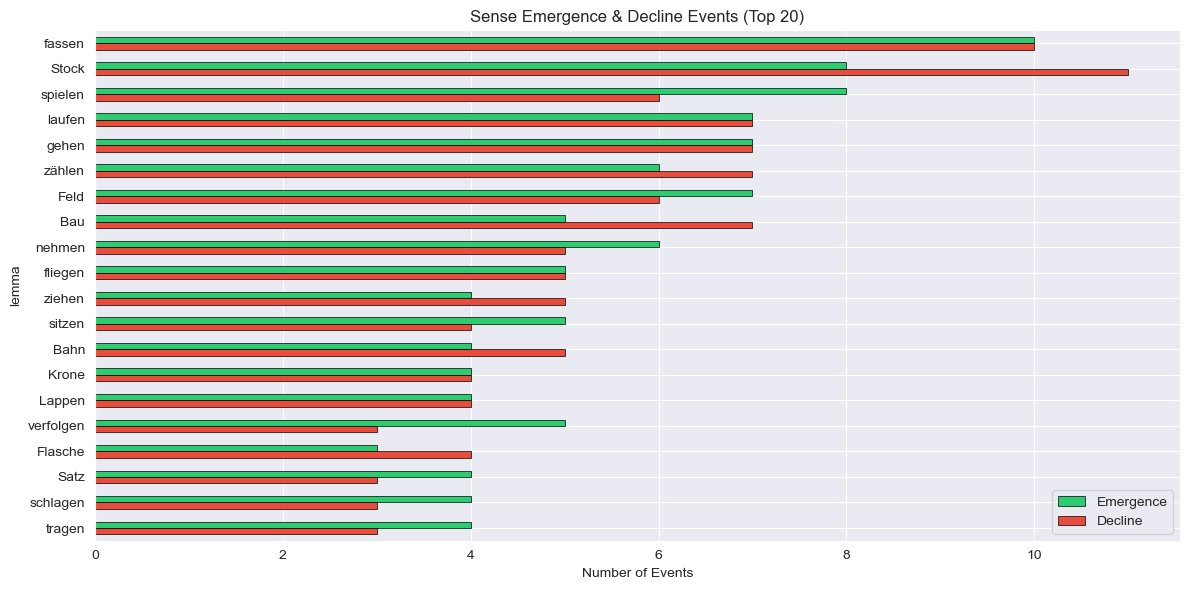

In [45]:
# Emergence & decline event counts per word
emerg_counts_all = emergence.groupby('lemma').size().rename('emergence')
decl_counts_all = decline.groupby('lemma').size().rename('decline')
event_counts = pd.concat([emerg_counts_all, decl_counts_all], axis=1).fillna(0).astype(int)
event_counts['total_events'] = event_counts['emergence'] + event_counts['decline']
event_counts = event_counts.sort_values('total_events', ascending=False).head(20)

fig, ax = plt.subplots(figsize=(12, 6))
event_counts[['emergence', 'decline']].plot.barh(
    ax=ax, color=['#2ecc71', '#e74c3c'], edgecolor='black', linewidth=0.5
)
ax.set_xlabel('Number of Events')
ax.set_title('Sense Emergence & Decline Events (Top 20)')
ax.legend(['Emergence', 'Decline'])
ax.invert_yaxis()
plt.tight_layout()
plt.show()

In [46]:
# Flag suspicious JSD=1.0 events with context counts
jsd_max = divergence[divergence['jsd'] >= 0.99].copy()

if len(jsd_max) > 0:
    # Annotate with context counts from decade_stats
    stats_lookup = decade_stats.set_index(['lemma', 'decade'])['n_contexts']
    jsd_max['n_contexts_from'] = jsd_max.apply(
        lambda r: stats_lookup.get((r['lemma'], r['decade_from']), 0), axis=1
    )
    jsd_max['n_contexts_to'] = jsd_max.apply(
        lambda r: stats_lookup.get((r['lemma'], r['decade_to']), 0), axis=1
    )
    jsd_max['min_contexts'] = jsd_max[['n_contexts_from', 'n_contexts_to']].min(axis=1)

    display(Markdown(f'### JSD >= 0.99 Events ({len(jsd_max)} total)'))
    display(
        jsd_max[['lemma', 'decade_from', 'decade_to', 'jsd', 'n_contexts_from', 'n_contexts_to', 'min_contexts']]
        .sort_values('min_contexts')
        .style.background_gradient(subset=['min_contexts'], cmap='RdYlGn')
        .format({'jsd': '{:.4f}'})
        .set_properties(**{'text-align': 'center'})
    )
else:
    print('No JSD >= 0.99 events found.')

No JSD >= 0.99 events found.


## 6. Sparse Data Audit

Many dramatic JSD=1.0 values may be artifacts of sparse data. This section investigates.

In [ ]:
# Annotate ALL divergence rows with context counts
stats_lookup = decade_stats.set_index(['lemma', 'decade'])['n_contexts']

div_annotated = divergence.copy()
div_annotated['n_contexts_from'] = div_annotated.apply(
    lambda r: stats_lookup.get((r['lemma'], r['decade_from']), 0), axis=1
)
div_annotated['n_contexts_to'] = div_annotated.apply(
    lambda r: stats_lookup.get((r['lemma'], r['decade_to']), 0), axis=1
)
div_annotated['min_contexts'] = div_annotated[['n_contexts_from', 'n_contexts_to']].min(axis=1)

In [ ]:
# Scatter: JSD vs min(n_contexts)
fig, ax = plt.subplots(figsize=(10, 6))
scatter = ax.scatter(
    div_annotated['min_contexts'], div_annotated['jsd'],
    alpha=0.5, c=div_annotated['jsd'], cmap='RdYlGn_r', edgecolors='black', linewidth=0.3, s=40
)
ax.axhline(y=0.99, color='red', linestyle='--', alpha=0.7, label='JSD=0.99')
ax.axvline(x=5, color='blue', linestyle='--', alpha=0.7, label='n=5 threshold')
ax.set_xlabel('Min Contexts (from or to decade)')
ax.set_ylabel('JSD')
ax.set_title('JSD vs Data Density — Do Extreme Values Come from Sparse Data?')
ax.legend()
plt.colorbar(scatter, ax=ax, label='JSD')
plt.tight_layout()
plt.show()

# Correlation
corr = div_annotated[['min_contexts', 'jsd']].corr().iloc[0, 1]
print(f'Correlation (min_contexts vs JSD): {corr:.3f}')

In [ ]:
# List word-decades with < 5 contexts
sparse_wd = decade_stats[decade_stats['n_contexts'] < 5][['lemma', 'decade', 'n_contexts', 'n_senses', 'dominant_sense']]
sparse_wd = sparse_wd.sort_values(['n_contexts', 'lemma'])

display(Markdown(f'### Word-Decades with < 5 Contexts ({len(sparse_wd)} total)'))
display(sparse_wd.style.set_properties(**{'text-align': 'center'}))

In [ ]:
# Reliability assessment
n_jsd_high = (div_annotated['jsd'] >= 0.99).sum()
n_jsd_high_sparse = ((div_annotated['jsd'] >= 0.99) & (div_annotated['min_contexts'] < 5)).sum()
n_jsd_high_reliable = ((div_annotated['jsd'] >= 0.99) & (div_annotated['min_contexts'] >= 5)).sum()

display(Markdown('### Reliability Summary'))
display(Markdown(
    f'- **JSD >= 0.99 events:** {n_jsd_high}\n'
    f'- **Of those, with min_contexts < 5 (likely artifacts):** {n_jsd_high_sparse} '
    f'({n_jsd_high_sparse/max(n_jsd_high,1)*100:.0f}%)\n'
    f'- **Of those, with min_contexts >= 5 (potentially real):** {n_jsd_high_reliable} '
    f'({n_jsd_high_reliable/max(n_jsd_high,1)*100:.0f}%)\n\n'
    f'**Recommendation:** Treat JSD values from word-decades with < 5 contexts as unreliable. '
    f'Focus manual validation on high-JSD events where both decades have >= 5 contexts.'
))

## 7. WWII Era Patterns

Focus on 1930s &rarr; 1940s &rarr; 1950s transitions.

The DWDS kern corpus contains texts from 1900–1999. The 1930s→1940s and 1940s→1950s transitions coincide with WWII and the immediate post-war period — a time of significant social and linguistic change in German.

Several words show unusually high JSD in this window. Hypothesized patterns:
- **Sense consolidation during the war** — language simplification, propaganda, restricted discourse
- **Post-war diversification** — new senses emerging in the 1950s as society and language opened up

**Caveat:** The 1940s is also one of the sparser decades in the corpus (fewer published texts), so some of these signals may still be data artifacts even after filtering. The context examples below are the most direct way to judge.

In [ ]:
# Top words by WWII-era divergence
wwii_decades = [1930, 1940, 1950]
wwii_div = divergence[
    divergence['decade_from'].isin(wwii_decades) &
    divergence['decade_to'].isin(wwii_decades)
].copy()

wwii_avg = wwii_div.groupby('lemma')['jsd'].mean().sort_values(ascending=False)

display(Markdown('### Top 15 Words by WWII-Era Avg JSD'))

fig, ax = plt.subplots(figsize=(12, 6))
wwii_avg.head(15).plot.barh(ax=ax, color='steelblue', edgecolor='black', linewidth=0.5)
ax.set_xlabel('Average JSD (1930s-1950s transitions)')
ax.set_title('Semantic Change Around WWII')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
# Sense trajectories for key WWII-era words
wwii_focus_words = ['schlagen', 'geben', 'handeln', 'werfen']
# Filter to words that actually exist in the data
wwii_focus_words = [w for w in wwii_focus_words if w in sense_counts['lemma'].values]

if wwii_focus_words:
    n_cols = 2
    n_rows = (len(wwii_focus_words) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 5 * n_rows), squeeze=False)

    for idx, lemma in enumerate(wwii_focus_words):
        row, col = divmod(idx, n_cols)
        ax = axes[row][col]

        lc = sense_counts[sense_counts['lemma'] == lemma]
        if len(lc) == 0:
            ax.set_title(f'{lemma} (no data)')
            continue

        pivot = lc.pivot(index='decade', columns='predicted_sense_id', values='proportion').fillna(0)
        col_order = pivot.sum().sort_values(ascending=False).index
        pivot = pivot[col_order]
        pivot.plot.area(ax=ax, alpha=0.7, linewidth=0.5, legend=False)

        # Highlight WWII decades
        ax.axvspan(1930, 1950, alpha=0.1, color='red', label='WWII era')
        ax.set_title(f'{lemma}', fontsize=12)
        ax.set_ylim(0, 1)
        ax.set_xlabel('Decade')
        ax.set_ylabel('Proportion')

    for idx in range(len(wwii_focus_words), n_rows * n_cols):
        row, col = divmod(idx, n_cols)
        axes[row][col].set_visible(False)

    fig.suptitle('WWII-Era Sense Trajectories', fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()
else:
    print('None of the WWII focus words found in data.')

In [ ]:
# Context examples: 1930s vs 1940s for WWII focus words
if wwii_focus_words:
    for lemma in wwii_focus_words:
        preds_lemma = predictions[predictions['lemma'] == lemma]
        display(Markdown(f'### {lemma}: 1930s vs 1940s Contexts'))

        for dec in [1930, 1940]:
            dec_preds = preds_lemma[preds_lemma['decade'] == dec]
            if len(dec_preds) == 0:
                display(Markdown(f'*No {dec}s contexts*'))
                continue

            display(Markdown(f'**{dec}s** ({len(dec_preds)} contexts):'))
            samples = dec_preds.sample(n=min(3, len(dec_preds)), random_state=42)
            for _, row in samples.iterrows():
                sense_info = f"{row['predicted_sense_id']}"
                if 'sense_class' in row and pd.notna(row.get('sense_class')):
                    sense_info += f" ({row['sense_class']})"
                sent = str(row['sentence'])[:250] + ('...' if len(str(row['sentence'])) > 250 else '')
                display(Markdown(f'- [{sense_info}, conf={row["confidence"]:.3f}] *{sent}*'))

## 8. Case Study Candidates

Select words suitable for a diachronic case study. Selection criteria (all must hold):

1. **Large change** — avg coarse JSD in top quartile (across all 81 non-excluded words)
2. **Monotonic trend** — at least one sense shows a sustained directional shift (Spearman |ρ| ≥ 0.6 over decades)
3. **Dense data** — ≥ 8 of 10 decades present with ≥ 10 contexts each
4. **Not a known artifact** — excluded words list does not apply

Words that pass all four criteria are flagged as **strong** candidates. Words passing 3/4 are **marginal**.

In [ ]:
from scipy.stats import spearmanr

ALL_DECADES = list(range(1900, 2000, 10))  # 10 reference decades

# ── Criterion 1: avg coarse JSD (top quartile) ─────────────────────────────────────────
avg_jsd_coarse = (divergence_coarse[~divergence_coarse['lemma'].isin(EXCLUDE_WORDS)]
                  .groupby('lemma')['jsd'].mean())
jsd_threshold = avg_jsd_coarse.quantile(0.75)

# ── Criterion 2: monotonicity — max |Spearman ρ| across all senses ───────────────────────
def monotonicity_score(lemma: str) -> tuple[float, str]:
    """Return (max |ρ|, sense_id) for the most monotonic sense of this lemma."""
    lc = sense_counts_coarse[sense_counts_coarse['lemma'] == lemma]
    best_rho, best_sense = 0.0, ''
    for sense_id, grp in lc.groupby('predicted_sense_id'):
        grp = grp.set_index('decade').reindex(ALL_DECADES)
        proportions = grp['proportion'].values
        valid = ~pd.isna(proportions)
        if valid.sum() < 6:
            continue
        decades_valid = [ALL_DECADES[i] for i in range(10) if valid[i]]
        props_valid   = proportions[valid]
        rho, _ = spearmanr(decades_valid, props_valid)
        if abs(rho) > abs(best_rho):
            best_rho, best_sense = rho, sense_id
    return round(best_rho, 3), best_sense

mono_results = {lemma: monotonicity_score(lemma) for lemma in avg_jsd_coarse.index}
mono_rho   = pd.Series({l: v[0] for l, v in mono_results.items()})
mono_sense = pd.Series({l: v[1] for l, v in mono_results.items()})

# ── Criterion 3: data density ─────────────────────────────────────────────────
stats_coarse_filtered = decade_stats_coarse[~decade_stats_coarse['lemma'].isin(EXCLUDE_WORDS)]
decade_coverage = (stats_coarse_filtered[stats_coarse_filtered['n_contexts'] >= 10]
                   .groupby('lemma')['decade'].count()
                   .reindex(avg_jsd_coarse.index, fill_value=0))

# ── Build candidate table ─────────────────────────────────────────────────────
candidates = pd.DataFrame({
    'avg_jsd':         avg_jsd_coarse,
    'mono_rho':        mono_rho.abs(),
    'mono_rho_signed': mono_rho,
    'mono_sense':      mono_sense,
    'dense_decades':   decade_coverage,
}).sort_values('avg_jsd', ascending=False)

candidates['c1_large_change'] = candidates['avg_jsd']      >= jsd_threshold
candidates['c2_monotonic']    = candidates['mono_rho']      >= 0.6
candidates['c3_dense']        = candidates['dense_decades'] >= 8
candidates['criteria_met']    = candidates[['c1_large_change', 'c2_monotonic', 'c3_dense']].sum(axis=1)
candidates['strength']        = candidates['criteria_met'].map({3: 'STRONG', 2: 'marginal', 1: 'weak', 0: 'weak'})

display(Markdown(f'### Candidate Scoring (top 20 by avg coarse JSD, JSD threshold={jsd_threshold:.4f})'))
cols = ['avg_jsd', 'mono_rho', 'mono_sense', 'dense_decades',
        'c1_large_change', 'c2_monotonic', 'c3_dense', 'criteria_met', 'strength']
display(
    candidates.head(20)[cols].style
    .format({'avg_jsd': '{:.4f}', 'mono_rho': '{:.3f}', 'dense_decades': '{:.0f}'})
    .applymap(lambda v: 'background-color: #d4edda' if v is True else
                        ('background-color: #f8d7da' if v is False else ''),
              subset=['c1_large_change', 'c2_monotonic', 'c3_dense'])
    .applymap(lambda v: 'font-weight: bold; color: darkgreen' if v == 'STRONG' else
                        ('color: darkorange' if v == 'marginal' else ''),
              subset=['strength'])
    .set_properties(**{'text-align': 'center'})
)

strong   = candidates[candidates['strength'] == 'STRONG'].index.tolist()
marginal = candidates[candidates['strength'] == 'marginal'].index.tolist()
print(f'\nStrong candidates ({len(strong)}):  {strong}')
print(f'Marginal candidates ({len(marginal)}): {marginal[:10]}')

In [ ]:
# Sense trajectories for strong + top marginal candidates
# Each subplot: stacked area (proportions) + line for the most monotonic sense
plot_words = (strong + [w for w in marginal if w in candidates.head(20).index])[:12]

n_cols = 3
n_rows = (len(plot_words) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(17, 4.5 * n_rows), squeeze=False)

for idx, lemma in enumerate(plot_words):
    row, col = divmod(idx, n_cols)
    ax = axes[row][col]

    lc = sense_counts_coarse[sense_counts_coarse['lemma'] == lemma]
    if len(lc) == 0:
        ax.set_title(f'{lemma} (no data)')
        continue

    pivot = lc.pivot(index='decade', columns='predicted_sense_id', values='proportion').fillna(0)
    col_order = pivot.sum().sort_values(ascending=False).index
    pivot = pivot[col_order]
    pivot.columns = relabel_index(lemma, pivot.columns)
    pivot.plot.area(ax=ax, alpha=0.55, linewidth=0.3, legend=False)

    # Overlay the most monotonic sense as a thick line
    top_sense = candidates.loc[lemma, 'mono_sense']
    if top_sense and top_sense in lc['predicted_sense_id'].values:
        ts_data = lc[lc['predicted_sense_id'] == top_sense].set_index('decade')['proportion'].reindex(ALL_DECADES)
        ax.plot(ALL_DECADES, ts_data.values, color='black', linewidth=2.5,
                linestyle='--', label=f'ρ={candidates.loc[lemma, "mono_rho_signed"]:.2f}')
        ax.legend(fontsize=7, loc='upper right')

    strength_str = candidates.loc[lemma, 'strength']
    color = 'darkgreen' if strength_str == 'STRONG' else 'darkorange'
    jsd_val = candidates.loc[lemma, 'avg_jsd']
    ax.set_title(f'{lemma}  [{strength_str}]  JSD={jsd_val:.3f}', fontsize=10, color=color)
    ax.set_ylim(0, 1)
    ax.set_xlabel('Decade', fontsize=8)
    ax.set_ylabel('Proportion', fontsize=8)
    ax.tick_params(labelsize=8)

for idx in range(len(plot_words), n_rows * n_cols):
    row, col = divmod(idx, n_cols)
    axes[row][col].set_visible(False)

fig.suptitle('Case Study Candidates — Coarse Sense Trajectories\n'
             '(dashed black line = most monotonic sense, ρ = Spearman correlation with time)',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# Final verdict table — each candidate annotated with the direction of its key shift
def describe_shift(lemma: str) -> str:
    """Summarise the direction of the most monotonic sense's shift."""
    top_sense = candidates.loc[lemma, 'mono_sense']
    rho = candidates.loc[lemma, 'mono_rho_signed']
    label_str = sense_label(lemma, top_sense) if top_sense else '?'
    direction = 'rising' if rho > 0 else 'declining'
    return f'{label_str}  →  {direction} (ρ={rho:+.2f})'

verdict_lemmas = strong + [w for w in marginal if w in candidates.head(20).index]
verdict = candidates.loc[verdict_lemmas, ['avg_jsd', 'mono_rho', 'dense_decades', 'criteria_met', 'strength']].copy()
verdict['dominant_shift'] = [describe_shift(l) for l in verdict.index]
verdict['total_contexts'] = (decade_stats_coarse.groupby('lemma')['n_contexts']
                              .sum().reindex(verdict.index))

display(Markdown('### Final Verdict: Case Study Shortlist'))
display(
    verdict[['avg_jsd', 'mono_rho', 'dense_decades', 'total_contexts', 'strength', 'dominant_shift']].style
    .format({'avg_jsd': '{:.4f}', 'mono_rho': '{:.3f}',
             'dense_decades': '{:.0f}', 'total_contexts': '{:.0f}'})
    .applymap(lambda v: 'font-weight: bold; color: darkgreen' if v == 'STRONG' else
                        ('color: darkorange' if v == 'marginal' else ''),
              subset=['strength'])
    .set_properties(**{'text-align': 'left'})
    .set_properties(**{'text-align': 'center'},
                    subset=['avg_jsd', 'mono_rho', 'dense_decades', 'total_contexts', 'strength'])
)